# Adversarial Robustness of ResNet-18 vs VGG-16 on CIFAR-100 (v2)

Code for the paper **"Clean Accuracy Explains Most of the Robustness Gap: A Controlled Comparison of ResNet-18 and VGG-16 under Adversarial Training on CIFAR-100"** (M. Oryntay, A. Ghani). PDF: [`paper/`](../paper/). Training was split across several Colab/Kaggle sessions (12-hour limit). Runs finished in earlier sessions are imported in the first cell and skipped, so the outputs below show the training log of the last session (ResNet-18 AT resumed from epoch 26, VGG-16 standard and AT, seed 2) and the evaluation of all 12 models.

**Changes vs. the previous notebook**
1. **Bug fix:** images are no longer normalised in the DataLoader. Normalisation lives *inside* the model,
   so every attack works in pixel space `[0,1]` and `eps = 8/255` really means 8/255.
   (Before, torchattacks clamped *normalised* tensors to `[0,1]` and `eps` was in normalised units.)
2. SGD + LR schedule + weight decay instead of Adam/15 epochs; checkpoint selection on a held-out validation split (not on the test set).
3. Resume after Colab disconnects (checkpoint every epoch on Google Drive).
4. Several seeds, PGD-7 (as in the paper) **and** PGD-20 + AutoAttack, Macro-F1, NRR, logit-MSE (Wang & Liu, ICCV'25).
5. All results saved to JSON; figures and LaTeX table rows are produced from the JSON (no hard-coded numbers).
6. Fig. 2 (examples) uses the *trained* model and shows its predictions.

**Kaggle version.** Same recipe as the Colab notebook (do NOT change CFG except `seeds`). One seed per session.

**v3:** main checkpoint = `final` (last epoch); `best` reported as secondary. Adds AutoAttack for the final checkpoint and per-eps tables (NRR, conditional robust accuracy, logit-MSE ratio).

In [1]:
# Kaggle setup: needs Settings -> Accelerator: GPU, Internet: ON (phone-verified account)
!pip install -q git+https://github.com/fra31/auto-attack
import os, json, time, random, glob, math, shutil
import numpy as np
import torch, torch.nn as nn, torch.nn.functional as F
import torchvision, torchvision.transforms as T
import matplotlib.pyplot as plt

ROOT = '/kaggle/working/robust_v2'      # everything written here is saved as notebook output
DATA = '/kaggle/working/data'
os.makedirs(ROOT, exist_ok=True)

# Bring in earlier results (seed 0 from Colab, or outputs of previous Kaggle runs) that you added
# via "+ Add Input": any folder named robust_v2 under /kaggle/input is merged into ROOT.
for src_dir in glob.glob('/kaggle/input/**/robust_v2', recursive=True):
    for run in os.listdir(src_dir):
        s, d = f'{src_dir}/{run}', f'{ROOT}/{run}'
        if os.path.isdir(s) and not os.path.exists(d):
            shutil.copytree(s, d); print('imported', run)

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(device, torch.cuda.get_device_name(0) if device == 'cuda' else '', '| torch', torch.__version__)
assert device == 'cuda', 'Turn on GPU: Settings -> Accelerator'
torch.backends.cudnn.benchmark = True

  Preparing metadata (setup.py) ... done
imported vgg16_at_s1
imported resnet18_std_s1
imported vgg16_at_s0
imported resnet18_std_s2
imported resnet18_at_s0
imported resnet18_at_s1
imported vgg16_std_s0
imported resnet18_at_s2
imported vgg16_std_s1
imported resnet18_std_s0
cuda Tesla T4 | torch 2.11.0+cu128


## 1. Config — everything that goes into Section IV (Experimental Setup)

In [2]:
CFG = dict(
    epochs=50,            # 50 on a T4 ~= 40 min (std ResNet) / 2.3 h (AT ResNet); raise to 100 if you have time
    batch_size=128,
    lr=0.1, momentum=0.9, weight_decay=5e-4,
    lr_milestones=(0.5, 0.75), lr_gamma=0.1,   # x0.1 at 50% and 75% of training
    val_size=1000,        # held-out training images for checkpoint selection
    # mixed-loss AT (Eq. (4) in the paper)
    train_eps=4/255, train_alpha=1/255, train_steps=3, clean_weight=0.5,
    # evaluation
    eval_eps=[0, 2/255, 4/255, 8/255],
    pgd7=dict(steps=7, alpha_frac=0.25),       # alpha = eps/4, random start (same as before)
    pgd20=dict(steps=20, alpha=2/255),          # standard PGD-20
    aa_n=1000,            # AutoAttack on the first N test images (10000 is very slow on a T4)
    seeds=[2],   # <-- ONE seed per Kaggle session (12 h limit)
    archs=['resnet18', 'vgg16'],
    modes=['std', 'at'],
)
json.dump(CFG, open(f'{ROOT}/config_{"_".join(map(str, CFG["seeds"]))}.json', 'w'), indent=2)
CFG

{'epochs': 50,
 'batch_size': 128,
 'lr': 0.1,
 'momentum': 0.9,
 'weight_decay': 0.0005,
 'lr_milestones': (0.5, 0.75),
 'lr_gamma': 0.1,
 'val_size': 1000,
 'train_eps': 0.01568627450980392,
 'train_alpha': 0.00392156862745098,
 'train_steps': 3,
 'clean_weight': 0.5,
 'eval_eps': [0,
  0.00784313725490196,
  0.01568627450980392,
  0.03137254901960784],
 'pgd7': {'steps': 7, 'alpha_frac': 0.25},
 'pgd20': {'steps': 20, 'alpha': 0.00784313725490196},
 'aa_n': 1000,
 'seeds': [2],
 'archs': ['resnet18', 'vgg16'],
 'modes': ['std', 'at']}

## 2. Data — **no Normalize here** (pixels stay in [0,1])

In [3]:
MEAN, STD = (0.5071, 0.4867, 0.4408), (0.2675, 0.2565, 0.2761)

def get_loaders(seed):
    tr_tf = T.Compose([T.RandomCrop(32, padding=4), T.RandomHorizontalFlip(), T.ToTensor()])
    te_tf = T.ToTensor()
    full_tr = torchvision.datasets.CIFAR100(DATA, train=True, download=True, transform=tr_tf)
    full_tr_plain = torchvision.datasets.CIFAR100(DATA, train=True, download=True, transform=te_tf)
    test = torchvision.datasets.CIFAR100(DATA, train=False, download=True, transform=te_tf)
    idx = torch.randperm(len(full_tr), generator=torch.Generator().manual_seed(seed)).tolist()
    val_idx, tr_idx = idx[:CFG['val_size']], idx[CFG['val_size']:]
    mk = lambda ds, bs, sh: torch.utils.data.DataLoader(ds, bs, shuffle=sh, num_workers=2,
                                                        pin_memory=True, drop_last=sh)
    return (mk(torch.utils.data.Subset(full_tr, tr_idx), CFG['batch_size'], True),
            mk(torch.utils.data.Subset(full_tr_plain, val_idx), 256, False),
            mk(test, 256, False), test.classes)

## 3. Models — normalisation is the first layer of the model

In [4]:
class Normalize(nn.Module):
    def __init__(self, mean, std):
        super().__init__()
        self.register_buffer('m', torch.tensor(mean).view(1, 3, 1, 1))
        self.register_buffer('s', torch.tensor(std).view(1, 3, 1, 1))
    def forward(self, x): return (x - self.m) / self.s

def resnet18_cifar(nc=100):
    m = torchvision.models.resnet18(weights=None)
    m.conv1 = nn.Conv2d(3, 64, 3, 1, 1, bias=False)
    m.maxpool = nn.Identity()
    m.fc = nn.Linear(m.fc.in_features, nc)
    return m

def vgg16_cifar(nc=100):   # same architecture as in the previous notebook
    m = torchvision.models.vgg16_bn(weights=None)
    m.avgpool = nn.AdaptiveAvgPool2d((1, 1))
    m.classifier = nn.Sequential(
        nn.Linear(512, 512), nn.BatchNorm1d(512), nn.ReLU(True), nn.Dropout(0.5),
        nn.Linear(512, 512), nn.BatchNorm1d(512), nn.ReLU(True), nn.Dropout(0.5),
        nn.Linear(512, nc))
    return m

def build(arch):
    net = {'resnet18': resnet18_cifar, 'vgg16': vgg16_cifar}[arch]()
    return nn.Sequential(Normalize(MEAN, STD), net).to(device)

for a in CFG['archs']:
    print(a, f"{sum(p.numel() for p in build(a).parameters())/1e6:.2f}M params")  # -> paper, Section III

resnet18 11.22M params
vgg16 15.30M params


## 4. Attacks (own implementation, inputs in [0,1])

In [5]:
def fgsm(model, x, y, eps):
    if eps == 0: return x
    x = x.clone().requires_grad_(True)
    g, = torch.autograd.grad(F.cross_entropy(model(x), y), x)
    return (x + eps * g.sign()).clamp(0, 1).detach()

def pgd(model, x, y, eps, alpha, steps, random_start=True):
    if eps == 0: return x
    d = torch.empty_like(x).uniform_(-eps, eps) if random_start else torch.zeros_like(x)
    d = ((x + d).clamp(0, 1) - x).detach()
    for _ in range(steps):
        d.requires_grad_(True)
        g, = torch.autograd.grad(F.cross_entropy(model(x + d), y), d)
        d = (d + alpha * g.sign()).clamp(-eps, eps)
        d = ((x + d).clamp(0, 1) - x).detach()
    return (x + d).detach()

@torch.no_grad()
def acc(model, loader, attack=None, max_batches=None):
    model.eval(); c = n = 0
    for i, (x, y) in enumerate(loader):
        if max_batches and i >= max_batches: break
        x, y = x.to(device), y.to(device)
        if attack is not None:
            with torch.enable_grad(): x = attack(model, x, y)
        c += (model(x).argmax(1) == y).sum().item(); n += y.numel()
    return 100 * c / n

## 5. Training with resume (safe against Colab disconnects)

In [6]:
def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

def train(arch, mode, seed):
    run = f'{ROOT}/{arch}_{mode}_s{seed}'; os.makedirs(run, exist_ok=True)
    if os.path.exists(f'{run}/DONE'): print('skip', run); return run
    set_seed(seed)
    tr, val, _, _ = get_loaders(seed)
    model = build(arch)
    opt = torch.optim.SGD(model.parameters(), lr=CFG['lr'], momentum=CFG['momentum'],
                          weight_decay=CFG['weight_decay'])
    E = CFG['epochs']
    sched = torch.optim.lr_scheduler.MultiStepLR(
        opt, [int(E * f) for f in CFG['lr_milestones']], CFG['lr_gamma'])
    start, best, log = 0, -1, []
    if os.path.exists(f'{run}/last.pt'):                      # resume
        ck = torch.load(f'{run}/last.pt', map_location=device)
        model.load_state_dict(ck['model']); opt.load_state_dict(ck['opt'])
        sched.load_state_dict(ck['sched']); start, best, log = ck['epoch'], ck['best'], ck['log']
        print(f'resume {run} from epoch {start}')
    for ep in range(start, E):
        model.train(); t0 = time.time(); tot = 0
        for x, y in tr:
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
            if mode == 'std':
                loss = F.cross_entropy(model(x), y)
            else:
                model.eval()   # craft x_adv without updating BN statistics
                x_adv = pgd(model, x, y, CFG['train_eps'], CFG['train_alpha'], CFG['train_steps'])
                model.train()
                w = CFG['clean_weight']
                loss = w * F.cross_entropy(model(x), y) + (1 - w) * F.cross_entropy(model(x_adv), y)
            opt.zero_grad(set_to_none=True); loss.backward(); opt.step(); tot += loss.item()
        sched.step()
        row = dict(epoch=ep + 1, loss=tot / len(tr), lr=opt.param_groups[0]['lr'],
                   val_clean=acc(model, val))
        if mode == 'at':
            row['val_pgd10'] = acc(model, val, lambda m, x, y: pgd(m, x, y, 8/255, 2/255, 10))
        score = row['val_pgd10'] if mode == 'at' else row['val_clean']
        if score > best:
            best = score; torch.save(model.state_dict(), f'{run}/best.pt'); row['saved_best'] = True
        row['time_s'] = round(time.time() - t0, 1); log.append(row); print(row)
        torch.save(dict(model=model.state_dict(), opt=opt.state_dict(), sched=sched.state_dict(),
                        epoch=ep + 1, best=best, log=log), f'{run}/last.pt')
        json.dump(log, open(f'{run}/train_log.json', 'w'), indent=1)
    torch.save(model.state_dict(), f'{run}/final.pt'); open(f'{run}/DONE', 'w').close()
    return run

## 6. Run trainings for the seeds listed in CFG['seeds']
Finished runs are skipped. Use **Save Version -> Save & Run All (Commit)** so it keeps running with the tab closed.

In [7]:
for seed in CFG['seeds']:
    for arch in CFG['archs']:
        for mode in CFG['modes']:
            train(arch, mode, seed)

skip /kaggle/working/robust_v2/resnet18_std_s2


100%|██████████| 169M/169M [52:04<00:00, 54.1kB/s]


resume /kaggle/working/robust_v2/resnet18_at_s2 from epoch 26
{'epoch': 27, 'loss': 1.0192504149144856, 'lr': 0.010000000000000002, 'val_clean': 70.2, 'val_pgd10': 9.9, 'time_s': 185.9}
{'epoch': 28, 'loss': 0.9395267286225764, 'lr': 0.010000000000000002, 'val_clean': 70.2, 'val_pgd10': 9.7, 'time_s': 174.8}
{'epoch': 29, 'loss': 0.876152000502142, 'lr': 0.010000000000000002, 'val_clean': 70.3, 'val_pgd10': 9.4, 'time_s': 175.2}
{'epoch': 30, 'loss': 0.8185305423761537, 'lr': 0.010000000000000002, 'val_clean': 70.3, 'val_pgd10': 9.9, 'time_s': 176.4}
{'epoch': 31, 'loss': 0.7704775643910413, 'lr': 0.010000000000000002, 'val_clean': 69.7, 'val_pgd10': 10.0, 'time_s': 175.0}
{'epoch': 32, 'loss': 0.7220383526767111, 'lr': 0.010000000000000002, 'val_clean': 69.8, 'val_pgd10': 9.0, 'time_s': 174.5}
{'epoch': 33, 'loss': 0.6774333010169225, 'lr': 0.010000000000000002, 'val_clean': 70.3, 'val_pgd10': 9.4, 'time_s': 175.5}
{'epoch': 34, 'loss': 0.6336822313944083, 'lr': 0.010000000000000002, 

## 7. Evaluation

In [8]:
def macro_f1(p, t, nc=100):
    f = []
    for c in range(nc):
        tp = ((p == c) & (t == c)).sum(); fp = ((p == c) & (t != c)).sum(); fn = ((p != c) & (t == c)).sum()
        f.append(0 if 2 * tp + fp + fn == 0 else 2 * tp / (2 * tp + fp + fn))
    return float(np.mean(f))

nrr = lambda c, r: 0.0 if c + r == 0 else 2 * c * r / (c + r)

def evaluate(run, ckpt='best.pt', autoattack=True):
    out = f'{run}/eval_{ckpt[:-3]}.json'
    if os.path.exists(out): return json.load(open(out))
    arch = os.path.basename(run).split('_')[0]
    model = build(arch); model.load_state_dict(torch.load(f'{run}/{ckpt}', map_location=device)); model.eval()
    _, _, te, _ = get_loaders(0)
    res = dict(run=run, ckpt=ckpt, results={})
    for eps in CFG['eval_eps']:
        P = {k: [] for k in ['clean', 'fgsm', 'pgd7', 'pgd20']}; Y = []; mse_def = []; mse_fail = []
        for x, y in te:
            x, y = x.to(device), y.to(device); Y.append(y.cpu())
            with torch.no_grad(): z0 = model(x)
            xf = fgsm(model, x, y, eps)
            x7 = pgd(model, x, y, eps, eps * CFG['pgd7']['alpha_frac'], CFG['pgd7']['steps'])
            x20 = pgd(model, x, y, eps, CFG['pgd20']['alpha'], CFG['pgd20']['steps'])
            with torch.no_grad():
                z20 = model(x20)
                for k, xx in [('fgsm', xf), ('pgd7', x7)]: P[k].append(model(xx).argmax(1).cpu())
            P['clean'].append(z0.argmax(1).cpu()); P['pgd20'].append(z20.argmax(1).cpu())
            if eps > 0:   # perception consistency: logit MSE clean vs PGD-20, clean-correct samples only
                ok = z0.argmax(1) == y; mse = ((z20 - z0) ** 2).mean(1)
                mse_def.append(mse[ok & (z20.argmax(1) == y)].cpu())
                mse_fail.append(mse[ok & (z20.argmax(1) != y)].cpu())
        Y = torch.cat(Y).numpy(); r = {}
        for k, v in P.items():
            p = torch.cat(v).numpy(); r[f'{k}_acc'] = 100 * float((p == Y).mean()); r[f'{k}_f1'] = macro_f1(p, Y)
        r['nrr_pgd7'] = nrr(r['clean_acc'], r['pgd7_acc']); r['nrr_pgd20'] = nrr(r['clean_acc'], r['pgd20_acc'])
        if eps > 0:
            d, f = torch.cat(mse_def), torch.cat(mse_fail)
            r.update(mse_defended=float(d.mean()) if len(d) else None,
                     mse_failed=float(f.mean()) if len(f) else None, n_def=len(d), n_fail=len(f))
        res['results'][f'{round(eps * 255)}/255'] = r; print(os.path.basename(run), round(eps * 255), r)

    # sanity check against gradient masking: a huge eps must drive accuracy to ~0%
    res['sanity_pgd_eps64'] = acc(model, te, lambda m, x, y: pgd(m, x, y, 64/255, 8/255, 20), max_batches=4)

    if autoattack:
        from autoattack import AutoAttack
        xs = torch.cat([x for x, _ in te])[:CFG['aa_n']]; ys = torch.cat([y for _, y in te])[:CFG['aa_n']]
        aa = AutoAttack(model, norm='Linf', eps=8/255, version='standard', device=device)
        xadv = aa.run_standard_evaluation(xs.to(device), ys.to(device), bs=250)
        with torch.no_grad(): p = model(xadv).argmax(1).cpu()
        a = 100 * float((p == ys).float().mean())
        with torch.no_grad(): clean_sub = 100 * float((model(xs.to(device)).argmax(1).cpu() == ys).float().mean())
        res['autoattack'] = dict(n=len(ys), acc=a, clean_on_subset=clean_sub, nrr_aa=nrr(clean_sub, a))
    json.dump(res, open(out, 'w'), indent=2)
    return res

In [9]:
for run in sorted(glob.glob(f'{ROOT}/*_s*')):
    if os.path.exists(f'{run}/DONE'):
        evaluate(run, 'best.pt', autoattack=True)
        evaluate(run, 'final.pt', autoattack=False)   # best vs final -> robust-overfitting check

resnet18_at_s2 0 {'clean_acc': 67.91, 'clean_f1': 0.6766705425372733, 'fgsm_acc': 67.91, 'fgsm_f1': 0.6766705425372733, 'pgd7_acc': 67.91, 'pgd7_f1': 0.6766705425372733, 'pgd20_acc': 67.91, 'pgd20_f1': 0.6766705425372733, 'nrr_pgd7': 67.91, 'nrr_pgd20': 67.91}
resnet18_at_s2 2 {'clean_acc': 67.91, 'clean_f1': 0.6766705425372733, 'fgsm_acc': 50.519999999999996, 'fgsm_f1': 0.5014332313771097, 'pgd7_acc': 49.830000000000005, 'pgd7_f1': 0.4941255716793219, 'pgd20_acc': 48.980000000000004, 'pgd20_f1': 0.4852002717817628, 'nrr_pgd7': 57.48182945473076, 'nrr_pgd20': 56.91217041663102, 'mse_defended': 0.10829193145036697, 'mse_failed': 0.1525646448135376, 'n_def': 4898, 'n_fail': 1893}
resnet18_at_s2 4 {'clean_acc': 67.91, 'clean_f1': 0.6766705425372733, 'fgsm_acc': 35.77, 'fgsm_f1': 0.35541639769690386, 'pgd7_acc': 32.82, 'pgd7_f1': 0.32562855413745906, 'pgd20_acc': 30.130000000000003, 'pgd20_f1': 0.2978280474306176, 'nrr_pgd7': 44.25307654124889, 'nrr_pgd20': 41.74068339453285, 'mse_defended

In [10]:
# 7b. AutoAttack for the FINAL checkpoint (main checkpoint in the paper). Adds results to eval_final.json.
def add_autoattack(run, ckpt='final.pt'):
    out = f'{run}/eval_{ckpt[:-3]}.json'
    res = json.load(open(out))
    if 'autoattack' in res: return res
    from autoattack import AutoAttack
    arch = os.path.basename(run).split('_')[0]
    model = build(arch); model.load_state_dict(torch.load(f'{run}/{ckpt}', map_location=device)); model.eval()
    _, _, te, _ = get_loaders(0)
    xs = torch.cat([x for x, _ in te])[:CFG['aa_n']]; ys = torch.cat([y for _, y in te])[:CFG['aa_n']]
    aa = AutoAttack(model, norm='Linf', eps=8/255, version='standard', device=device)
    xadv = aa.run_standard_evaluation(xs.to(device), ys.to(device), bs=250)
    with torch.no_grad():
        p = model(xadv).argmax(1).cpu()
        clean_sub = 100 * float((model(xs.to(device)).argmax(1).cpu() == ys).float().mean())
    a = 100 * float((p == ys).float().mean())
    res['autoattack'] = dict(n=len(ys), acc=a, clean_on_subset=clean_sub, nrr_aa=nrr(clean_sub, a))
    json.dump(res, open(out, 'w'), indent=2); print(os.path.basename(run), 'AA(final) =', a)
    return res

for run in sorted(glob.glob(f'{ROOT}/*_s*')):
    if os.path.exists(f'{run}/DONE'):
        add_autoattack(run, 'final.pt')

setting parameters for standard version
using standard version including apgd-ce, apgd-t, fab-t, square.
initial accuracy: 69.90%
apgd-ce - 1/3 - 228 out of 250 successfully perturbed
apgd-ce - 2/3 - 226 out of 250 successfully perturbed
apgd-ce - 3/3 - 182 out of 199 successfully perturbed
robust accuracy after APGD-CE: 6.30% (total time 45.0 s)
apgd-t - 1/1 - 8 out of 63 successfully perturbed
robust accuracy after APGD-T: 5.50% (total time 82.1 s)
fab-t - 1/1 - 0 out of 55 successfully perturbed
robust accuracy after FAB-T: 5.50% (total time 144.5 s)
square - 1/1 - 0 out of 55 successfully perturbed
robust accuracy after SQUARE: 5.50% (total time 222.2 s)
max Linf perturbation: 0.03137, nan in tensor: 0, max: 1.00000, min: 0.00000
robust accuracy: 5.50%
resnet18_at_s0 AA(final) = 5.499999970197678
setting parameters for standard version
using standard version including apgd-ce, apgd-t, fab-t, square.
initial accuracy: 67.10%
apgd-ce - 1/3 - 228 out of 250 successfully perturbed
apgd

## 8. Tables for the paper: mean ± std over seeds, for the final (main) and best checkpoints

In [11]:
from collections import defaultdict
MAIN = 'final'   # main checkpoint in the paper; 'best' is reported as secondary
NAME = {'resnet18_std': 'ResNet-18 (standard)', 'resnet18_at': 'ResNet-18 (mixed AT)',
        'vgg16_std': 'VGG-16 (standard)', 'vgg16_at': 'VGG-16 (mixed AT)'}
order = ['resnet18_std', 'resnet18_at', 'vgg16_std', 'vgg16_at']

def load(ck):
    G = defaultdict(list)
    for f in sorted(glob.glob(f'{ROOT}/*_s*/eval_{ck}.json')):
        G[os.path.basename(os.path.dirname(f)).rsplit('_s', 1)[0]].append(json.load(open(f)))
    return G

def fm(v, d=2):
    v = [x for x in v if x is not None]
    if not v: return '--'
    return f'{np.mean(v):.{d}f}' if len(v) == 1 else f'{np.mean(v):.{d}f}$\\pm${np.std(v):.{d}f}'

summary = {}
for ck in [MAIN, 'best']:
    G = load(ck); summary[ck] = {}
    print(f'\n%%%%%%%%%%%%%%%% checkpoint = {ck} %%%%%%%%%%%%%%%%')
    print('% Table (eps=8/255): Clean acc & Clean F1 & FGSM & PGD-7 & PGD-20 & AA & NRR_AA')
    for m in order:
        if m not in G: continue
        R = [r['results']['8/255'] for r in G[m]]
        aa = [r.get('autoattack', {}).get('acc') for r in G[m]]
        na = [r.get('autoattack', {}).get('nrr_aa') for r in G[m]]
        print(f"{NAME[m]} & {fm([x['clean_acc'] for x in R])} & {fm([x['clean_f1'] for x in R], 3)} & "
              f"{fm([x['fgsm_acc'] for x in R])} & {fm([x['pgd7_acc'] for x in R])} & "
              f"{fm([x['pgd20_acc'] for x in R])} & {fm(aa)} & {fm(na)} \\\\   % n_seeds={len(R)}")
    print('% Per-eps: model & eps & Clean & PGD-7 & PGD-20 & NRR(PGD-20) & rho = cond. robust acc (%) & logit-MSE fail/def')
    for m in order:
        if m not in G: continue
        for e in ['2/255', '4/255', '8/255']:
            R = [r['results'][e] for r in G[m]]
            rho = [100 * x['n_def'] / (x['n_def'] + x['n_fail']) for x in R]
            rat = [x['mse_failed'] / x['mse_defended'] if x['n_def'] >= 30 else None for x in R]
            print(f"{NAME[m]} & {e} & {fm([x['clean_acc'] for x in R])} & {fm([x['pgd7_acc'] for x in R])} & "
                  f"{fm([x['pgd20_acc'] for x in R])} & {fm([x['nrr_pgd20'] for x in R])} & {fm(rho, 1)} & {fm(rat)} \\\\")
            summary[ck][f'{m}|{e}'] = dict(clean=[x['clean_acc'] for x in R], pgd7=[x['pgd7_acc'] for x in R],
                                           pgd20=[x['pgd20_acc'] for x in R], rho=rho, mse_ratio=rat)
    print('% Sanity (PGD eps=64/255 should be ~0%):', {m: [round(r['sanity_pgd_eps64'], 2) for r in G[m]] for m in G})
json.dump(summary, open(f'{ROOT}/summary.json', 'w'), indent=2)


%%%%%%%%%%%%%%%% checkpoint = final %%%%%%%%%%%%%%%%
% Table (eps=8/255): Clean acc & Clean F1 & FGSM & PGD-7 & PGD-20 & AA & NRR_AA
ResNet-18 (standard) & 74.96$\pm$0.03 & 0.750$\pm$0.000 & 6.68$\pm$0.47 & 0.01$\pm$0.01 & 0.00$\pm$0.00 & 0.00$\pm$0.00 & 0.00$\pm$0.00 \\   % n_seeds=3
ResNet-18 (mixed AT) & 69.81$\pm$0.04 & 0.697$\pm$0.000 & 17.37$\pm$0.12 & 10.27$\pm$0.30 & 7.10$\pm$0.16 & 5.77$\pm$0.31 & 10.64$\pm$0.53 \\   % n_seeds=3
VGG-16 (standard) & 61.84$\pm$0.15 & 0.622$\pm$0.001 & 6.19$\pm$0.43 & 0.22$\pm$0.09 & 0.07$\pm$0.06 & 0.00$\pm$0.00 & 0.00$\pm$0.00 \\   % n_seeds=3
VGG-16 (mixed AT) & 57.90$\pm$0.64 & 0.577$\pm$0.006 & 14.99$\pm$0.27 & 8.86$\pm$0.14 & 6.03$\pm$0.16 & 4.13$\pm$0.12 & 7.73$\pm$0.22 \\   % n_seeds=3
% Per-eps: model & eps & Clean & PGD-7 & PGD-20 & NRR(PGD-20) & rho = cond. robust acc (%) & logit-MSE fail/def
ResNet-18 (standard) & 2/255 & 74.96$\pm$0.03 & 2.60$\pm$0.15 & 3.06$\pm$0.20 & 5.89$\pm$0.36 & 4.1$\pm$0.3 & 2.74$\pm$0.16 \\
ResNet-18 (standa

## 9. Fig. 3 — accuracy vs eps (final checkpoint, mean ± std)

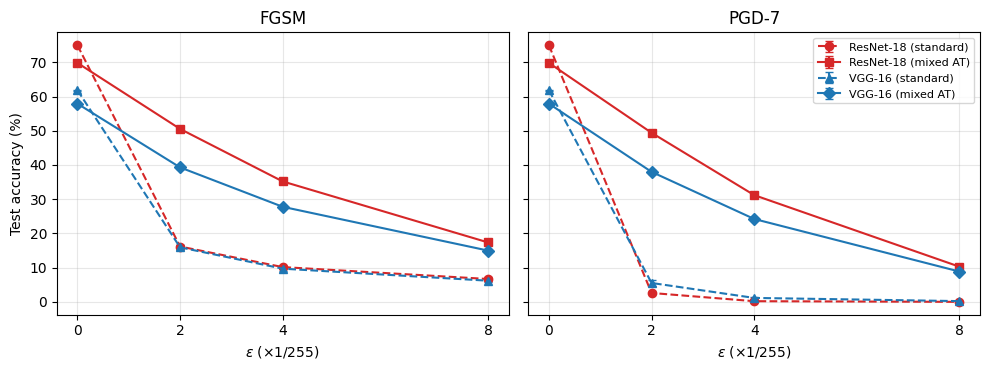

In [12]:
G = load(MAIN)   # main checkpoint
eps_keys = [f'{round(e*255)}/255' for e in CFG['eval_eps']]
xs = [0, 2, 4, 8]
style = {'resnet18_std': ('tab:red', '--', 'o'), 'resnet18_at': ('tab:red', '-', 's'),
         'vgg16_std': ('tab:blue', '--', '^'), 'vgg16_at': ('tab:blue', '-', 'D')}
fig, axs = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True)
for ax, atk, title in [(axs[0], 'fgsm_acc', 'FGSM'), (axs[1], 'pgd7_acc', 'PGD-7')]:
    for k in order:
        if k not in G: continue
        M = np.array([[r['results'][e][atk] for e in eps_keys] for r in G[k]])
        c, ls, mk = style[k]
        ax.errorbar(xs, M.mean(0), yerr=M.std(0), color=c, ls=ls, marker=mk, capsize=3, label=NAME[k])
    ax.set_title(title); ax.set_xlabel(r'$\epsilon$ (×1/255)'); ax.set_xticks(xs); ax.grid(alpha=.3)
axs[0].set_ylabel('Test accuracy (%)'); axs[1].legend(fontsize=8)
plt.tight_layout(); plt.savefig(f'{ROOT}/fig2_eps_curves.png', dpi=300, bbox_inches='tight'); plt.show()

## 10. Fig. 2 — examples with the *trained* standard ResNet-18 and its predictions

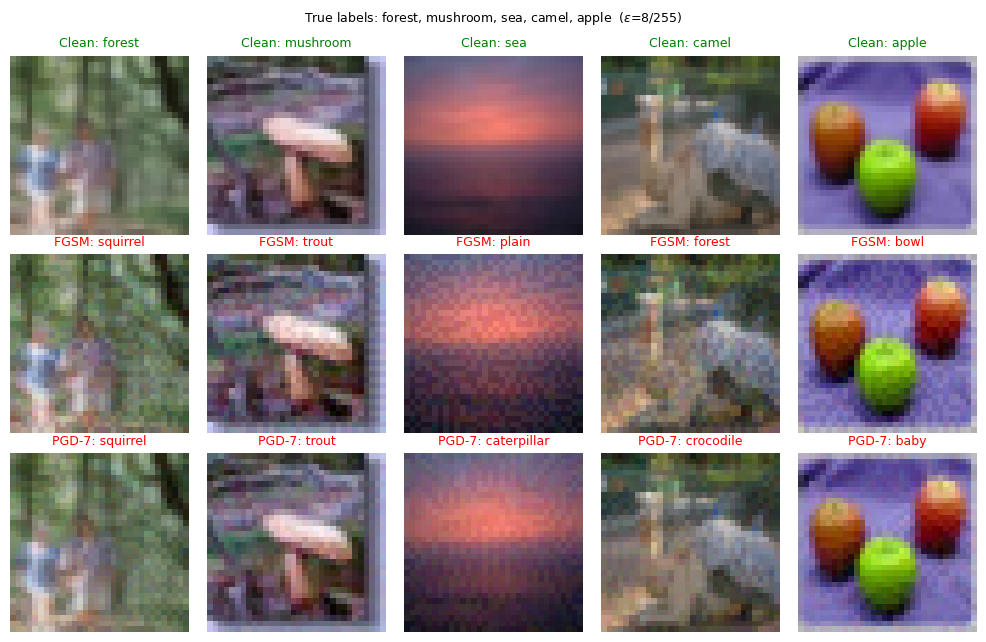

In [13]:
_, _, te, classes = get_loaders(0)
m = build('resnet18'); m.load_state_dict(torch.load(f'{ROOT}/resnet18_std_s0/best.pt', map_location=device)); m.eval()
x, y = next(iter(te)); x, y = x[:64].to(device), y[:64].to(device)
with torch.no_grad(): ok = (m(x).argmax(1) == y).nonzero().flatten()[:5]   # images the model gets right
x, y = x[ok], y[ok]
xf = fgsm(m, x, y, 8/255); xp = pgd(m, x, y, 8/255, 2/255, 7)
with torch.no_grad(): pc, pf, pp = [m(v).argmax(1) for v in (x, xf, xp)]
fig, axs = plt.subplots(3, 5, figsize=(10, 6.5))
for i in range(5):
    for r, (img, pred, name) in enumerate([(x, pc, 'Clean'), (xf, pf, 'FGSM'), (xp, pp, 'PGD-7')]):
        axs[r, i].imshow(img[i].permute(1, 2, 0).cpu()); axs[r, i].axis('off')
        col = 'green' if pred[i] == y[i] else 'red'
        axs[r, i].set_title(f'{name}: {classes[pred[i]]}', color=col, fontsize=9)
plt.suptitle(r'True labels: ' + ', '.join(classes[c] for c in y.tolist()) + r'  ($\epsilon$=8/255)', fontsize=9)
plt.tight_layout(); plt.savefig(f'{ROOT}/fig1_examples.png', dpi=300, bbox_inches='tight'); plt.show()